# Experiment 7 – Autoencoders, CAE, Denoising AE, VAE (MNIST)
Run cells top to bottom. All plots are saved to `/content/Experiment7_Plots`.

## Task 0 – Setup, data, metrics, plotting utilities

In [1]:
import os, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from skimage.metrics import structural_similarity as ssim_fn

keras.utils.set_random_seed(42)
OUT = '/content/Experiment7_Plots'
os.makedirs(OUT, exist_ok=True)

# bold labels / titles / ticks everywhere
plt.rcParams.update({'font.weight':'bold','axes.labelweight':'bold','axes.titleweight':'bold',
                     'figure.titleweight':'bold','axes.labelsize':12,'axes.titlesize':13})

def bold_legend(ax, **kw):
    leg = ax.legend(prop={'weight':'bold'}, **kw)
    if leg.get_title().get_text():
        leg.get_title().set_fontweight('bold')
    return leg

def save(fig, name):
    fig.savefig(os.path.join(OUT, name), dpi=200, bbox_inches='tight')
    plt.show()

# ---- data: 10,000 train (9,000 train + 1,000 val) and 2,000 test ----
(x_all, y_all), (x_te_all, y_te_all) = keras.datasets.mnist.load_data()
x_all = (x_all[:10000].astype('float32') / 255.)[..., None]
x_test = (x_te_all[:2000].astype('float32') / 255.)[..., None]
y_test = y_te_all[:2000]
x_train, x_val = x_all[:9000], x_all[9000:]
flat = lambda a: a.reshape(len(a), -1)
xtr_f, xva_f, xte_f = flat(x_train), flat(x_val), flat(x_test)
print(x_train.shape, x_val.shape, x_test.shape)

# ---- metrics ----
def per_image_mse(x, xh):
    return np.mean((flat(x) - flat(xh))**2, axis=1)

def evaluate(x, xh):
    x = x.reshape(-1, 28, 28); xh = xh.reshape(-1, 28, 28)
    mse = np.mean((x - xh)**2)
    mae = np.mean(np.abs(x - xh))
    s = np.mean([ssim_fn(a, b, data_range=1.0) for a, b in zip(x, xh)])
    return mse, mae, s

# ---- image-grid plot (rows = image types, columns = samples) ----
def grid_rows(rows, row_labels, fname, title, col_titles=None, cmaps=None):
    n = rows[0].shape[0]
    fig, axes = plt.subplots(len(rows), n, figsize=(1.4*n, 1.6*len(rows)+0.8), squeeze=False)
    for r, (imgs, lab) in enumerate(zip(rows, row_labels)):
        for c in range(n):
            ax = axes[r, c]
            ax.imshow(imgs[c].reshape(28, 28), cmap=(cmaps[r] if cmaps else 'gray'), vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(lab, rotation=0, ha='right', va='center', fontsize=11)
            if r == 0 and col_titles is not None:
                ax.set_title(col_titles[c], fontsize=9)
    fig.suptitle(title, fontsize=14, y=1.02)
    save(fig, fname)

def loss_plot(tr, va, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ep = np.arange(1, len(tr) + 1)
    ax.plot(ep, tr, lw=2, marker='o', ms=3, label='Training Loss')
    ax.plot(ep, va, lw=2, marker='s', ms=3, label='Validation Loss')
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(alpha=0.3)
    bold_legend(ax)
    save(fig, fname)

results = {}   # consolidated results

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(9000, 28, 28, 1) (1000, 28, 28, 1) (2000, 28, 28, 1)


## Task 1 – Fully Connected Autoencoder (latent = 16)

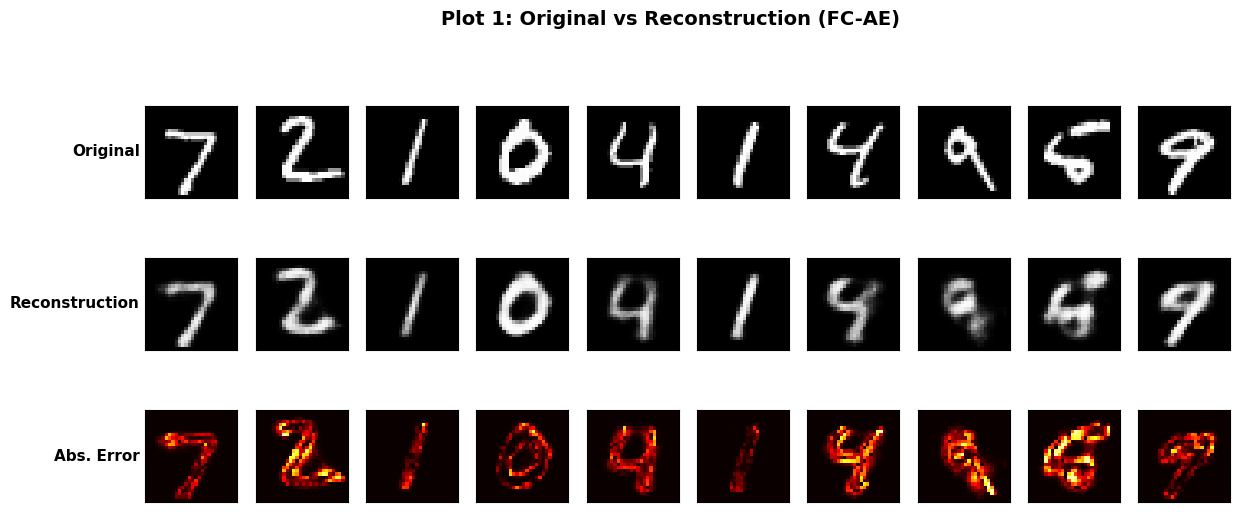

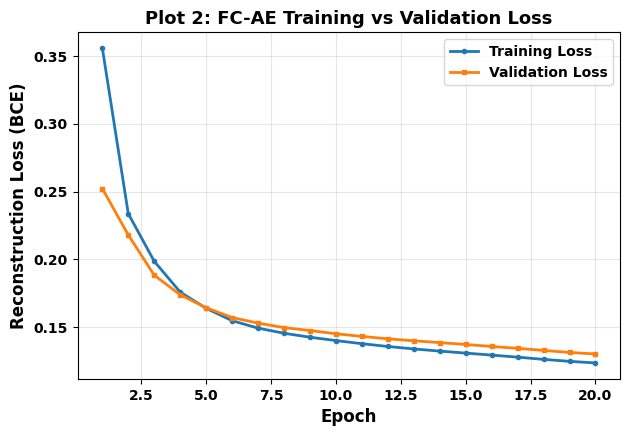

Final train loss 0.1236 | val loss 0.1303
   Metric    Value
 Test MSE 0.022110
 Test MAE 0.058131
Mean SSIM 0.737771


In [2]:
def build_fc_ae(latent=16):
    inp = keras.Input((784,))
    h = layers.Dense(128, activation='relu')(inp)
    h = layers.Dense(32, activation='relu')(h)
    z = layers.Dense(latent, activation='relu')(h)
    h = layers.Dense(32, activation='relu')(z)
    h = layers.Dense(128, activation='relu')(h)
    out = layers.Dense(784, activation='sigmoid')(h)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return m

fc_ae = build_fc_ae(16)
t0 = time.time()
h_fc = fc_ae.fit(xtr_f, xtr_f, epochs=20, batch_size=128,
                 validation_data=(xva_f, xva_f), verbose=0)
t_fc = time.time() - t0
xh_fc = fc_ae.predict(xte_f, verbose=0).reshape(-1, 28, 28, 1)

# Plot 1: original vs reconstruction (+ error map)
idx = np.arange(10)
grid_rows([x_test[idx], xh_fc[idx], np.abs(x_test[idx] - xh_fc[idx])],
          ['Original', 'Reconstruction', 'Abs. Error'],
          '01_fc_original_vs_reconstruction.png',
          'Plot 1: Original vs Reconstruction (FC-AE)', cmaps=['gray', 'gray', 'hot'])

# Plot 2: training vs validation loss
loss_plot(h_fc.history['loss'], h_fc.history['val_loss'], 'Reconstruction Loss (BCE)',
          'Plot 2: FC-AE Training vs Validation Loss', '02_fc_train_val_loss.png')
print(f"Final train loss {h_fc.history['loss'][-1]:.4f} | val loss {h_fc.history['val_loss'][-1]:.4f}")

# Metrics
m_fc = evaluate(x_test, xh_fc)
results['FC Autoencoder'] = (*m_fc, fc_ae.count_params(), t_fc)
print(pd.DataFrame({'Metric': ['Test MSE', 'Test MAE', 'Mean SSIM'], 'Value': m_fc}).to_string(index=False))

## Task 2 – Convolutional Autoencoder + comparison with FC-AE

             Model      MSE      MAE     SSIM  Parameters
Fully Connected AE 0.022110 0.058131 0.737771      211040
  Convolutional AE 0.002616 0.015094 0.973534       74497


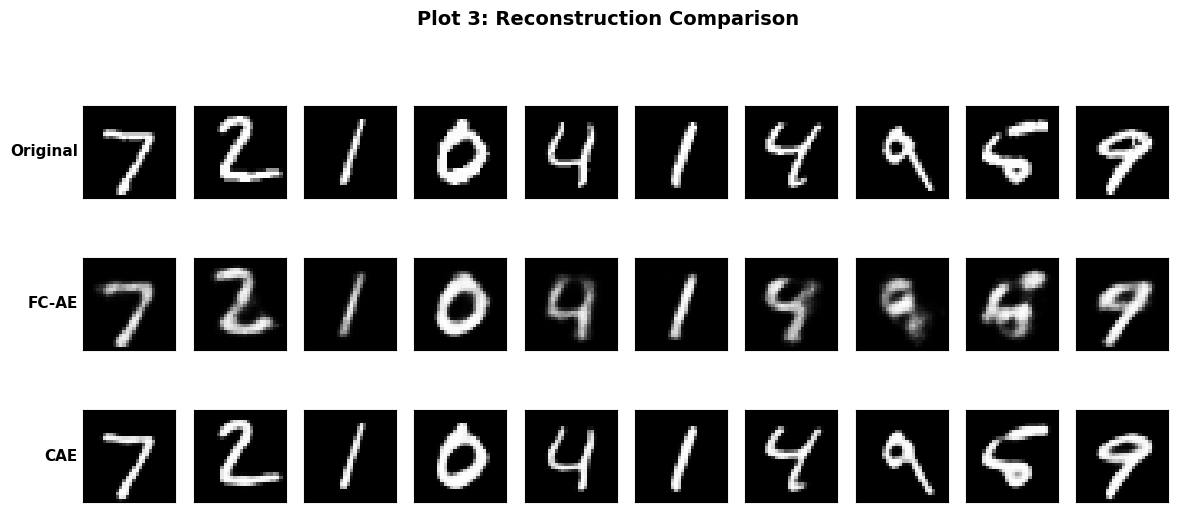

In [3]:
def build_cae():
    inp = keras.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)          # latent feature map 7x7x64
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return m

cae = build_cae()
t0 = time.time()
h_cae = cae.fit(x_train, x_train, epochs=20, batch_size=128,
                validation_data=(x_val, x_val), verbose=0)
t_cae = time.time() - t0
xh_cae = cae.predict(x_test, verbose=0)

m_cae = evaluate(x_test, xh_cae)
results['Conv. Autoencoder'] = (*m_cae, cae.count_params(), t_cae)
cmp = pd.DataFrame([[ 'Fully Connected AE', *m_fc, fc_ae.count_params()],
                    [ 'Convolutional AE', *m_cae, cae.count_params()]],
                   columns=['Model', 'MSE', 'MAE', 'SSIM', 'Parameters'])
print(cmp.to_string(index=False))

# Plot 3: Original -> FC-AE -> CAE
grid_rows([x_test[idx], xh_fc[idx], xh_cae[idx]],
          ['Original', 'FC-AE', 'CAE'],
          '03_fc_vs_cae_reconstruction.png', 'Plot 3: Reconstruction Comparison')

## Task 3 – Denoising Convolutional Autoencoder (Gaussian + Salt-and-Pepper)

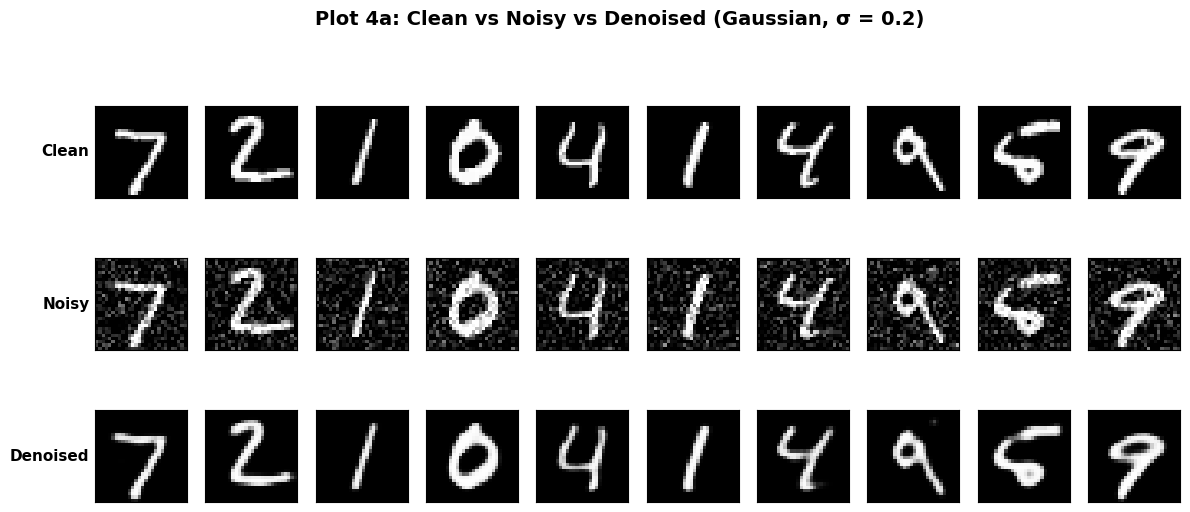

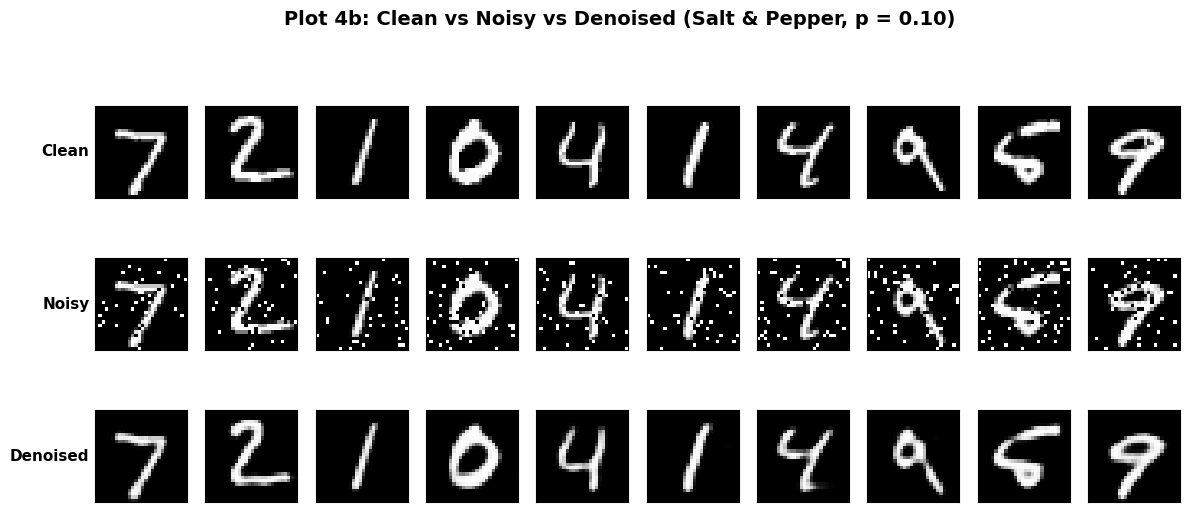

 Noise Level  Noisy MSE  Noisy MAE  Noisy SSIM  Denoised MSE  Denoised MAE  Denoised SSIM
         0.1     0.0054     0.0440      0.6791        0.0037        0.0180         0.9587
         0.2     0.0212     0.0866      0.5941        0.0047        0.0214         0.9445
         0.3     0.0467     0.1282      0.5091        0.0072        0.0296         0.8695


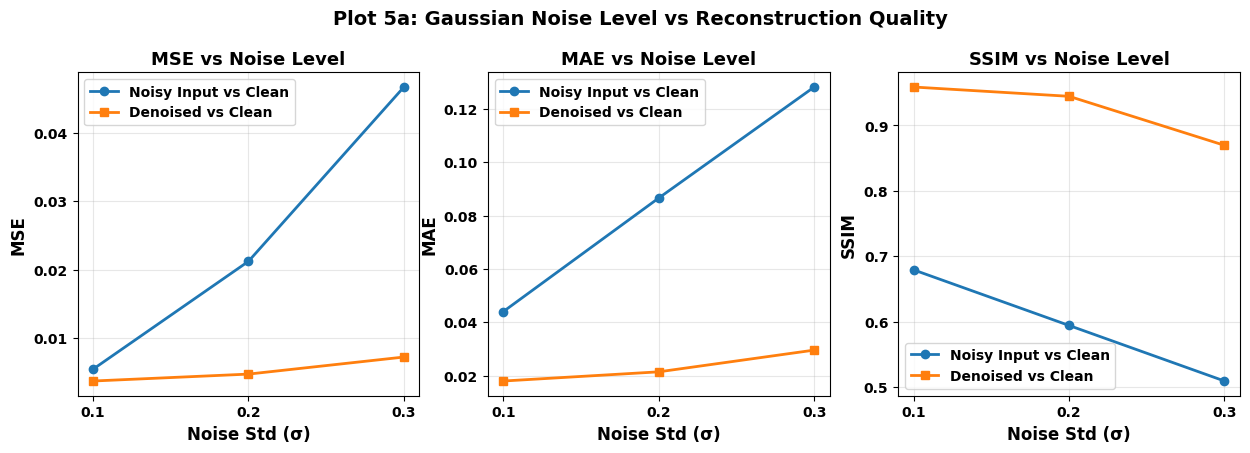

 Noise Level  Noisy MSE  Noisy MAE  Noisy SSIM  Denoised MSE  Denoised MAE  Denoised SSIM
        0.05     0.0239     0.0249      0.7114        0.0041        0.0190         0.9568
        0.10     0.0484     0.0502      0.5791        0.0050        0.0214         0.9436
        0.20     0.0966     0.1002      0.4461        0.0081        0.0290         0.8875


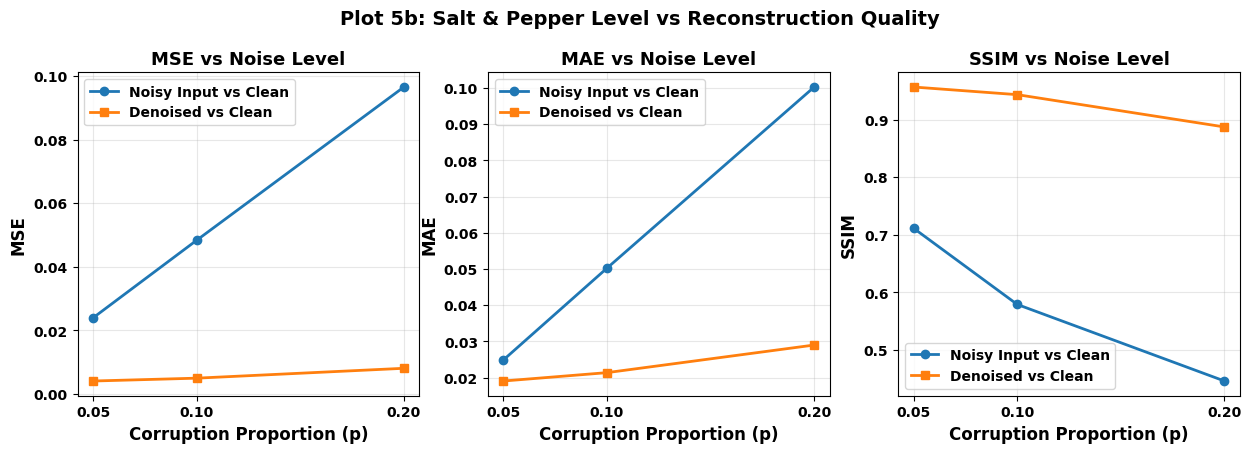

In [4]:
rng = np.random.default_rng(0)

def add_gaussian(x, sigma):
    return np.clip(x + rng.normal(0, sigma, x.shape), 0, 1).astype('float32')

def add_salt_pepper(x, p):
    noisy = x.copy()
    r = rng.random(x.shape)
    noisy[r < p/2] = 0.0            # pepper
    noisy[(r >= p/2) & (r < p)] = 1.0   # salt
    return noisy.astype('float32')

def train_denoiser(noise_fn, epochs=20):
    model = build_cae()
    x_val_noisy = noise_fn(x_val)      # fixed validation noise
    tr, va = [], []
    t0 = time.time()
    for _ in range(epochs):            # fresh noise every epoch
        h = model.fit(noise_fn(x_train), x_train, epochs=1, batch_size=128,
                      validation_data=(x_val_noisy, x_val), verbose=0)
        tr.append(h.history['loss'][0]); va.append(h.history['val_loss'][0])
    return model, tr, va, time.time() - t0

dcae_g, _, _, t_dg = train_denoiser(lambda a: add_gaussian(a, 0.2))       # trained at sigma = 0.2
dcae_sp, _, _, t_dsp = train_denoiser(lambda a: add_salt_pepper(a, 0.10)) # trained at p = 0.10

# Plot 4: clean vs noisy vs denoised (10 images, both noise types)
for name, model, noisy, fn, ttl in [
        ('gaussian', dcae_g, add_gaussian(x_test[idx], 0.2), '04a_denoising_gaussian.png', 'Plot 4a: Clean vs Noisy vs Denoised (Gaussian, σ = 0.2)'),
        ('salt_pepper', dcae_sp, add_salt_pepper(x_test[idx], 0.10), '04b_denoising_salt_pepper.png', 'Plot 4b: Clean vs Noisy vs Denoised (Salt & Pepper, p = 0.10)')]:
    den = model.predict(noisy, verbose=0)
    grid_rows([x_test[idx], noisy, den], ['Clean', 'Noisy', 'Denoised'], fn, ttl)

# Plot 5: noise level vs MSE / MAE / SSIM (separate axes per metric)
def noise_sweep(model, noise_fn, levels, xlabel, fname, title):
    rows = []
    for lv in levels:
        noisy = noise_fn(x_test, lv)
        den = model.predict(noisy, verbose=0)
        rows.append((lv, *evaluate(x_test, noisy), *evaluate(x_test, den)))
    df = pd.DataFrame(rows, columns=['Noise Level', 'Noisy MSE', 'Noisy MAE', 'Noisy SSIM',
                                     'Denoised MSE', 'Denoised MAE', 'Denoised SSIM'])
    print(df.round(4).to_string(index=False))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, met in zip(axes, ['MSE', 'MAE', 'SSIM']):
        ax.plot(df['Noise Level'], df[f'Noisy {met}'], marker='o', lw=2, label='Noisy Input vs Clean')
        ax.plot(df['Noise Level'], df[f'Denoised {met}'], marker='s', lw=2, label='Denoised vs Clean')
        ax.set_xlabel(xlabel); ax.set_ylabel(met); ax.set_title(f'{met} vs Noise Level')
        ax.set_xticks(df['Noise Level']); ax.grid(alpha=0.3); bold_legend(ax)
    fig.suptitle(title, fontsize=14, y=1.03)
    save(fig, fname)
    return df

df_g = noise_sweep(dcae_g, add_gaussian, [0.1, 0.2, 0.3], 'Noise Std (σ)',
                   '05a_noise_level_gaussian.png', 'Plot 5a: Gaussian Noise Level vs Reconstruction Quality')
df_sp = noise_sweep(dcae_sp, add_salt_pepper, [0.05, 0.10, 0.20], 'Corruption Proportion (p)',
                    '05b_noise_level_salt_pepper.png', 'Plot 5b: Salt & Pepper Level vs Reconstruction Quality')

# for consolidated table: Gaussian DCAE evaluated at sigma = 0.2
noisy02 = add_gaussian(x_test, 0.2)
m_d = evaluate(x_test, dcae_g.predict(noisy02, verbose=0))
results['Denoising CAE'] = (*m_d, dcae_g.count_params(), t_dg)

## Task 4 – Variational Autoencoder (latent = 2)

VAE trained in 475.1s | val recon 153.95 | val KL 5.79


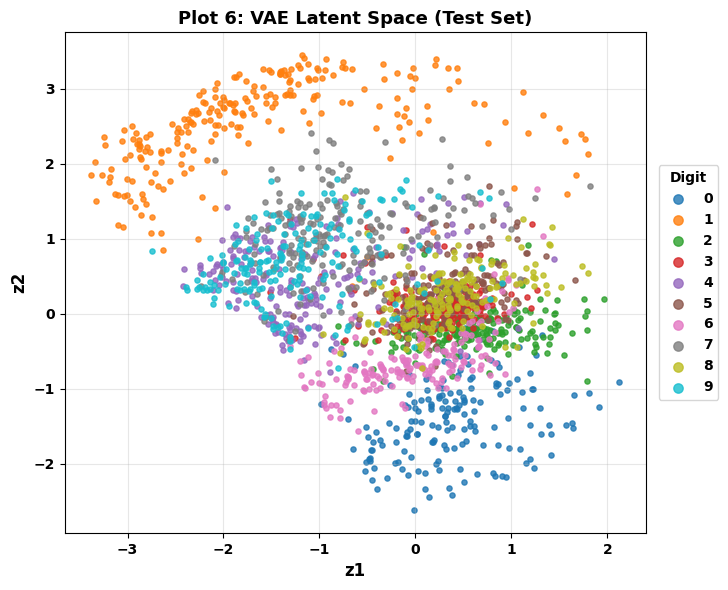

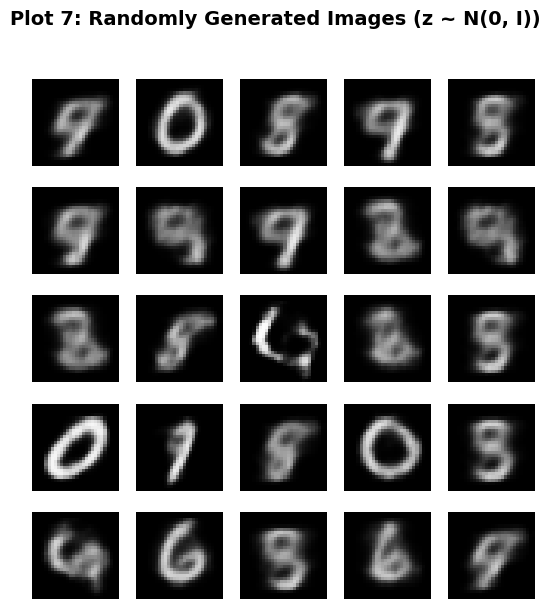

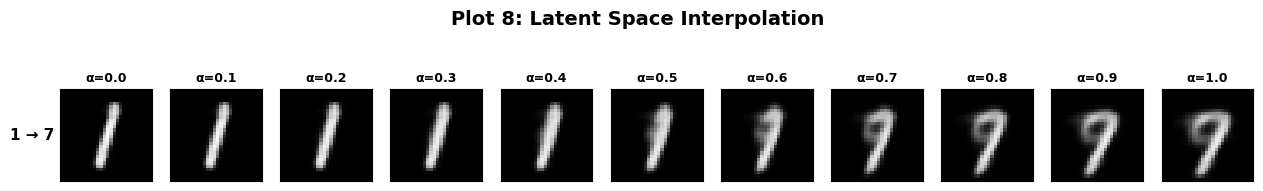

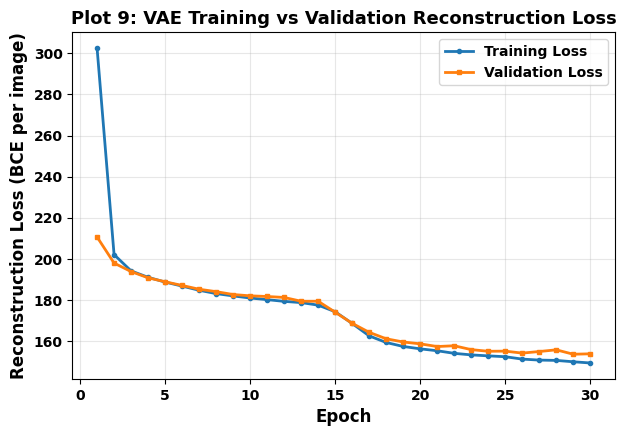

         VAE Metric    Value
Reconstruction Loss 151.4038
            KL Loss   5.7241
         Total Loss 157.1279
           Test MSE   0.0445
           Test MAE   0.1032
          Mean SSIM   0.4849


In [5]:
LATENT = 2

def build_vae_encoder():
    inp = keras.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, strides=2, padding='same', activation='relu')(inp)
    x = layers.Conv2D(64, 3, strides=2, padding='same', activation='relu')(x)
    x = layers.Flatten()(x)
    x = layers.Dense(16, activation='relu')(x)
    mu = layers.Dense(LATENT, name='mu')(x)
    logvar = layers.Dense(LATENT, name='log_var')(x)
    return keras.Model(inp, [mu, logvar], name='encoder')

def build_vae_decoder():
    inp = keras.Input((LATENT,))
    x = layers.Dense(7 * 7 * 64, activation='relu')(inp)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu')(x)
    out = layers.Conv2DTranspose(1, 3, padding='same', activation='sigmoid')(x)
    return keras.Model(inp, out, name='decoder')

enc, dec = build_vae_encoder(), build_vae_decoder()
opt = keras.optimizers.Adam(1e-3)

def vae_losses(x, training):
    mu, logvar = enc(x, training=training)
    eps = tf.random.normal(tf.shape(mu))
    z = mu + tf.exp(0.5 * logvar) * eps                     # reparameterization trick
    xh = dec(z, training=training)
    rec = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, xh), axis=[1, 2]))
    kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=1))
    return rec, kl

@tf.function
def vae_train_step(x):
    with tf.GradientTape() as tape:
        rec, kl = vae_losses(x, True)
        total = rec + kl
    vars_ = enc.trainable_variables + dec.trainable_variables
    opt.apply_gradients(zip(tape.gradient(total, vars_), vars_))
    return rec, kl

VAE_EPOCHS = 30
ds = tf.data.Dataset.from_tensor_slices(x_train).shuffle(9000, seed=42).batch(128)
vae_hist = {'rec': [], 'kl': [], 'val_rec': [], 'val_kl': []}
t0 = time.time()
for ep in range(VAE_EPOCHS):
    r_s, k_s, n = 0., 0., 0
    for xb in ds:
        r, k = vae_train_step(xb)
        r_s += float(r) * len(xb); k_s += float(k) * len(xb); n += len(xb)
    vr, vk = vae_losses(tf.constant(x_val), False)
    vae_hist['rec'].append(r_s / n); vae_hist['kl'].append(k_s / n)
    vae_hist['val_rec'].append(float(vr)); vae_hist['val_kl'].append(float(vk))
t_vae = time.time() - t0
print(f"VAE trained in {t_vae:.1f}s | val recon {vae_hist['val_rec'][-1]:.2f} | val KL {vae_hist['val_kl'][-1]:.2f}")

# Plot 6: 2-D latent space (means of encoded test images)
mu_test, _ = enc.predict(x_test, verbose=0)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
cmap = plt.get_cmap('tab10')
for d in range(10):
    m = y_test == d
    ax.scatter(mu_test[m, 0], mu_test[m, 1], s=14, color=cmap(d), label=str(d), alpha=0.8)
ax.set_xlabel('z1'); ax.set_ylabel('z2'); ax.set_title('Plot 6: VAE Latent Space (Test Set)')
ax.grid(alpha=0.3); bold_legend(ax, title='Digit', loc='center left', bbox_to_anchor=(1.01, 0.5), markerscale=1.8)
save(fig, '06_vae_latent_space.png')

# Plot 7: 25 randomly generated images, z ~ N(0, I)
rng_gen = np.random.default_rng(1)
gen = dec.predict(rng_gen.standard_normal((25, LATENT)).astype('float32'), verbose=0)
fig, axes = plt.subplots(5, 5, figsize=(6.5, 6.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(gen[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1); ax.axis('off')
fig.suptitle('Plot 7: Randomly Generated Images (z ~ N(0, I))', fontsize=14)
save(fig, '07_vae_generated_samples.png')

# Plot 8: latent-space interpolation between two digits
digit_A, digit_B = 1, 7
zA = mu_test[np.where(y_test == digit_A)[0][0]]
zB = mu_test[np.where(y_test == digit_B)[0][0]]
alphas = np.round(np.linspace(0, 1, 11), 1)
z_int = np.array([(1 - a) * zA + a * zB for a in alphas], dtype='float32')
interp = dec.predict(z_int, verbose=0)
grid_rows([interp], [f'{digit_A} → {digit_B}'], '08_vae_interpolation.png',
          'Plot 8: Latent Space Interpolation', col_titles=[f'α={a}' for a in alphas])

# Plot 9: VAE training vs validation reconstruction loss
loss_plot(vae_hist['rec'], vae_hist['val_rec'], 'Reconstruction Loss (BCE per image)',
          'Plot 9: VAE Training vs Validation Reconstruction Loss', '09_vae_train_val_recon_loss.png')

# VAE metrics (losses use sampled z; MSE/MAE/SSIM use deterministic z = mu)
rec_t, kl_t = vae_losses(tf.constant(x_test), False)
rec_t, kl_t = float(rec_t), float(kl_t)
xh_vae = dec.predict(mu_test, verbose=0)
m_v = evaluate(x_test, xh_vae)
vae_params = enc.count_params() + dec.count_params()
results['VAE'] = (*m_v, vae_params, t_vae)
print(pd.DataFrame({'VAE Metric': ['Reconstruction Loss', 'KL Loss', 'Total Loss', 'Test MSE', 'Test MAE', 'Mean SSIM'],
                    'Value': [rec_t, kl_t, rec_t + kl_t, *m_v]}).round(4).to_string(index=False))

## Task 5 – Reconstruction-error distribution + high-error images (Conv. AE)

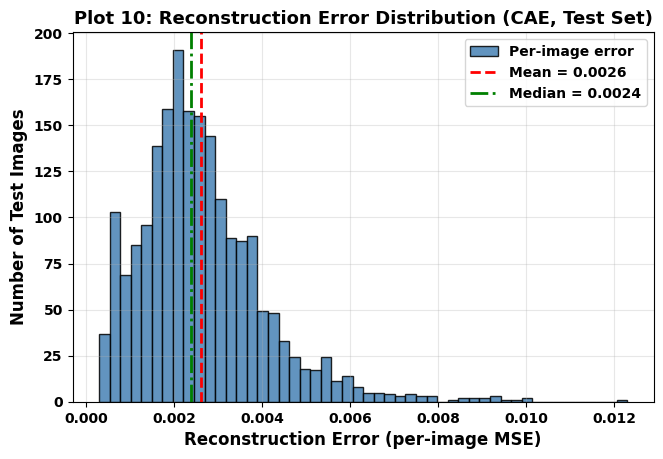

min 0.00029 | median 0.00239 | mean 0.00262 | max 0.01229 | std 0.00144


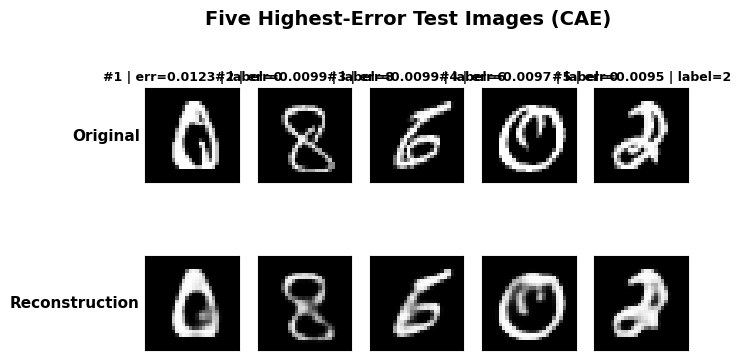

In [8]:
err = per_image_mse(x_test, xh_cae)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.hist(err, bins=50, color='steelblue', edgecolor='black', alpha=0.85, label='Per-image error')
ax.axvline(err.mean(), color='red', ls='--', lw=2, label=f'Mean = {err.mean():.4f}')
ax.axvline(np.median(err), color='green', ls='-.', lw=2, label=f'Median = {np.median(err):.4f}')
ax.set_xlabel('Reconstruction Error (per-image MSE)'); ax.set_ylabel('Number of Test Images')
ax.set_title('Plot 10: Reconstruction Error Distribution (CAE, Test Set)'); bold_legend(ax); ax.grid(alpha=0.3)
save(fig, '10_reconstruction_error_distribution.png')
print(f"min {err.min():.5f} | median {np.median(err):.5f} | mean {err.mean():.5f} | max {err.max():.5f} | std {err.std():.5f}")

top5 = np.argsort(err)[-5:][::-1]
grid_rows([x_test[top5], xh_cae[top5]], ['Original', 'Reconstruction'],
          '10b_top5_high_error_images.png', 'Five Highest-Error Test Images (CAE)',
          col_titles=[f'#{i+1} | err={err[j]:.4f} | label={y_test[j]}' for i, j in enumerate(top5)])

## Task 6 – Latent-dimension study (FC-AE, dz = 2, 8, 16, 32)

 Latent Dimension     MSE    SSIM  Parameters
                2 0.04784 0.42565      210130
                8 0.02889 0.66196      210520
               16 0.02211 0.73777      211040
               32 0.02100 0.75052      212080


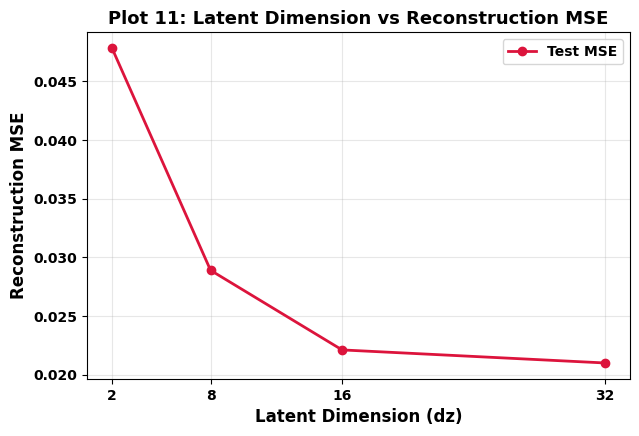

In [6]:
rows = []
for dz in [2, 8, 16, 32]:
    keras.utils.set_random_seed(42)
    m = build_fc_ae(dz)
    m.fit(xtr_f, xtr_f, epochs=20, batch_size=128, validation_data=(xva_f, xva_f), verbose=0)
    xh = m.predict(xte_f, verbose=0)
    mse, mae, s = evaluate(x_test, xh)
    rows.append((dz, mse, s, m.count_params()))
df_dz = pd.DataFrame(rows, columns=['Latent Dimension', 'MSE', 'SSIM', 'Parameters'])
print(df_dz.round(5).to_string(index=False))

# Plot 11: latent dimension vs MSE
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df_dz['Latent Dimension'], df_dz['MSE'], marker='o', lw=2, color='crimson', label='Test MSE')
ax.set_xticks(df_dz['Latent Dimension'])
ax.set_xlabel('Latent Dimension (dz)'); ax.set_ylabel('Reconstruction MSE')
ax.set_title('Plot 11: Latent Dimension vs Reconstruction MSE'); ax.grid(alpha=0.3); bold_legend(ax)
save(fig, '11_latent_dim_vs_mse.png')

## Task 7 – Consolidated results

In [7]:
final = pd.DataFrame(results, index=['MSE', 'MAE', 'SSIM', 'Parameters', 'Time (s)']).T
final['Parameters'] = final['Parameters'].astype(int)
print(final.round(5).to_string())
print('\nSaved plots:'); print(*sorted(os.listdir(OUT)), sep='\n')

                       MSE      MAE     SSIM  Parameters   Time (s)
FC Autoencoder     0.02211  0.05813  0.73777      211040   45.78359
Conv. Autoencoder  0.00262  0.01509  0.97353       74497  750.30521
Denoising CAE      0.00470  0.02142  0.94406       74497  724.93165
VAE                0.04452  0.10320  0.48494      134165  475.10325

Saved plots:
01_fc_original_vs_reconstruction.png
02_fc_train_val_loss.png
03_fc_vs_cae_reconstruction.png
04a_denoising_gaussian.png
04b_denoising_salt_pepper.png
05a_noise_level_gaussian.png
05b_noise_level_salt_pepper.png
06_vae_latent_space.png
07_vae_generated_samples.png
08_vae_interpolation.png
09_vae_train_val_recon_loss.png
11_latent_dim_vs_mse.png


 Latent Dimension     MSE     MAE    SSIM  Parameters
                4 0.03994 0.09350 0.55224      102725
                8 0.02672 0.06627 0.69946      127817
               16 0.01610 0.04462 0.82241      178001
               32 0.00850 0.02950 0.90912      278369


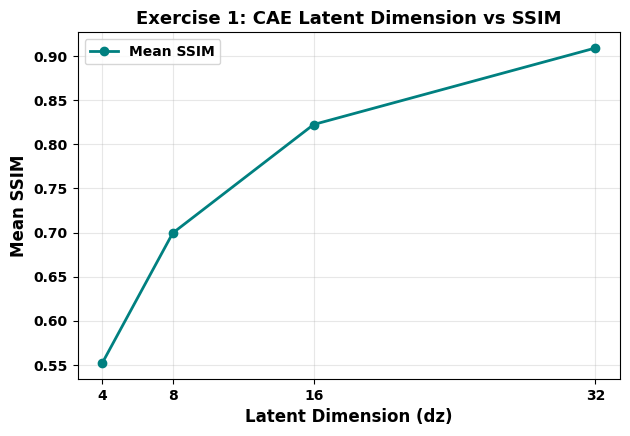

In [11]:
def build_cae_dz(dz):
    inp = keras.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)     # 7x7x64
    shape_before = (7, 7, 64)
    x = layers.Flatten()(x)
    z = layers.Dense(dz, activation='relu', name='latent')(x)
    x = layers.Dense(int(np.prod(shape_before)), activation='relu')(z)
    x = layers.Reshape(shape_before)(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return m

rows_ex1 = []
for dz in [4, 8, 16, 32]:
    keras.utils.set_random_seed(42)
    m = build_cae_dz(dz)
    m.fit(x_train, x_train, epochs=20, batch_size=128, validation_data=(x_val, x_val), verbose=0)
    xh = m.predict(x_test, verbose=0)
    mse, mae, s = evaluate(x_test, xh)
    rows_ex1.append((dz, mse, mae, s, m.count_params()))
df_ex1 = pd.DataFrame(rows_ex1, columns=['Latent Dimension', 'MSE', 'MAE', 'SSIM', 'Parameters'])
print(df_ex1.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df_ex1['Latent Dimension'], df_ex1['SSIM'], marker='o', lw=2, color='teal', label='Mean SSIM')
ax.set_xticks(df_ex1['Latent Dimension']); ax.set_xlabel('Latent Dimension (dz)'); ax.set_ylabel('Mean SSIM')
ax.set_title('Exercise 1: CAE Latent Dimension vs SSIM'); ax.grid(alpha=0.3); bold_legend(ax)
save(fig, '12_ex1_cae_latent_dim_vs_ssim.png')

            Noise Type     MSE     MAE    SSIM
      Gaussian (σ=0.2) 0.00471 0.02141 0.94434
Salt & Pepper (p=0.10) 0.00491 0.02124 0.94444


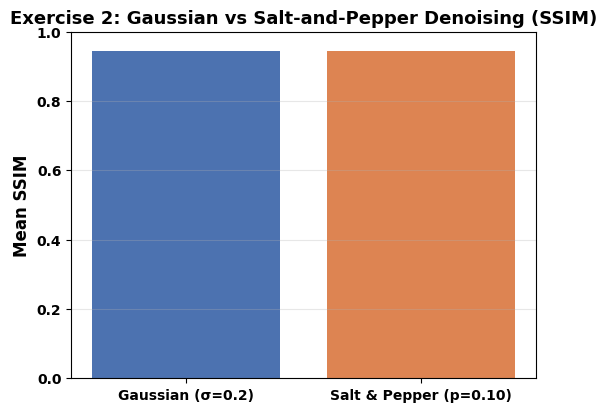

In [12]:
comp_gsp = pd.DataFrame([
    ['Gaussian (σ=0.2)', *evaluate(x_test, dcae_g.predict(add_gaussian(x_test, 0.2), verbose=0))],
    ['Salt & Pepper (p=0.10)', *evaluate(x_test, dcae_sp.predict(add_salt_pepper(x_test, 0.10), verbose=0))],
], columns=['Noise Type', 'MSE', 'MAE', 'SSIM'])
print(comp_gsp.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(comp_gsp['Noise Type'], comp_gsp['SSIM'], color=['#4C72B0', '#DD8452'])
ax.set_ylabel('Mean SSIM'); ax.set_title('Exercise 2: Gaussian vs Salt-and-Pepper Denoising (SSIM)')
ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis='y')
save(fig, '13_ex2_gaussian_vs_saltpepper.png')

In [13]:
dcae_low, _, _, _ = train_denoiser(lambda a: add_gaussian(a, 0.1))
dcae_high, _, _, _ = train_denoiser(lambda a: add_gaussian(a, 0.3))

rows_ex3 = []
for lab, model, lvl in [('Trained σ=0.1', dcae_low, 0.1), ('Trained σ=0.3', dcae_high, 0.3)]:
    noisy = add_gaussian(x_test, lvl)
    den = model.predict(noisy, verbose=0)
    rows_ex3.append((lab, *evaluate(x_test, den)))
df_ex3 = pd.DataFrame(rows_ex3, columns=['Model', 'MSE', 'MAE', 'SSIM'])
print(df_ex3.round(5).to_string(index=False))

        Model     MSE    MAE    SSIM
Trained σ=0.1 0.00346 0.0176 0.96162
Trained σ=0.3 0.00678 0.0267 0.91495


       Decoder Type     MSE     MAE    SSIM
   UpSampling2D CAE 0.00262 0.01509 0.97353
Conv2DTranspose CAE 0.00240 0.01445 0.97505


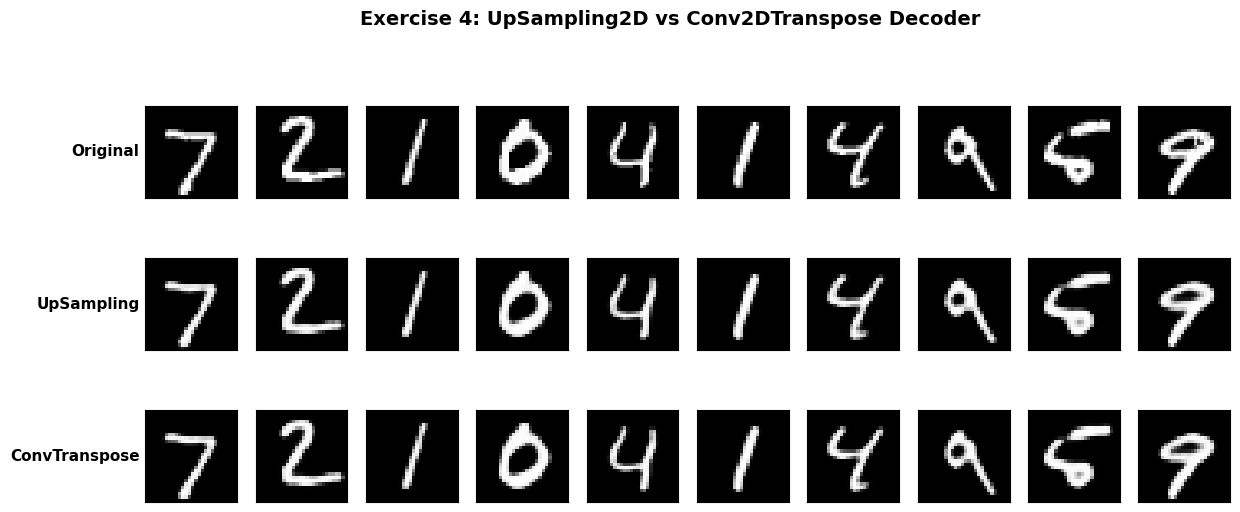

In [15]:
def build_cae_transpose():
    inp = keras.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, activation='relu', padding='same')(x)
    x = layers.Conv2DTranspose(1, 3, strides=2, activation='sigmoid', padding='same')(x)
    m = keras.Model(inp, x)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return m

cae_t = build_cae_transpose()
cae_t.fit(x_train, x_train, epochs=20, batch_size=128, validation_data=(x_val, x_val), verbose=0)
xh_cae_t = cae_t.predict(x_test, verbose=0)
m_ct = evaluate(x_test, xh_cae_t)
print(pd.DataFrame([['UpSampling2D CAE', *m_cae], ['Conv2DTranspose CAE', *m_ct]],
                   columns=['Decoder Type', 'MSE', 'MAE', 'SSIM']).round(5).to_string(index=False))

grid_rows([x_test[idx], xh_cae[idx], xh_cae_t[idx]], ['Original', 'UpSampling', 'ConvTranspose'],
          '14_ex4_upsampling_vs_transpose.png', 'Exercise 4: UpSampling2D vs Conv2DTranspose Decoder')

         VAE     MSE     MAE    SSIM
Latent dim 2 0.04452 0.10320 0.48494
Latent dim 8 0.03256 0.07814 0.64888


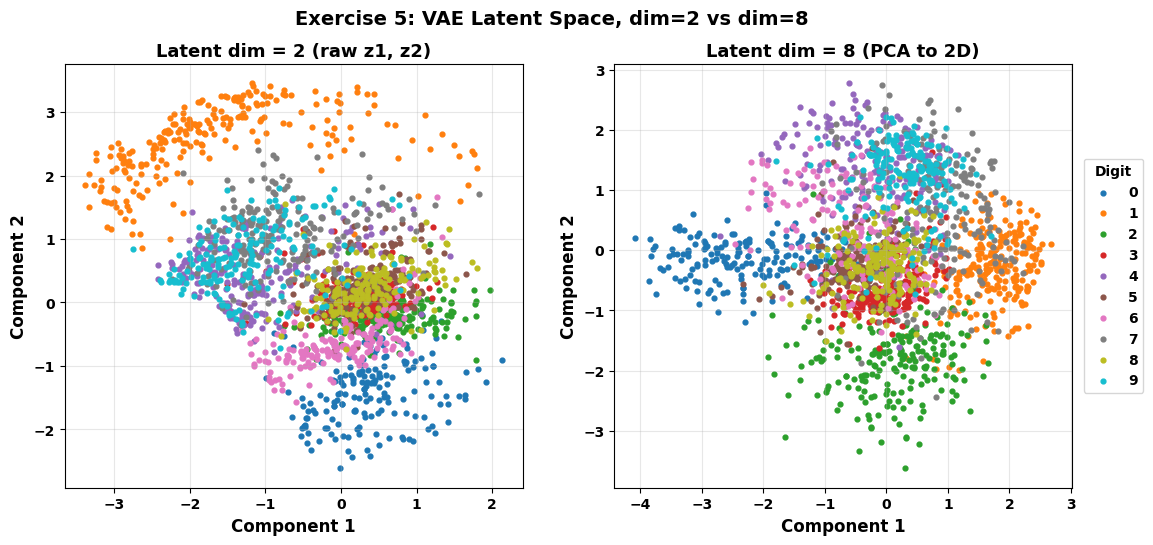

In [16]:
def train_vae(latent_dim, epochs=30, beta=1.0):
    e = build_vae_encoder() if latent_dim == LATENT else keras.Model(
        (inp := keras.Input((28, 28, 1))),
        [layers.Dense(latent_dim, name='mu')(
             h := layers.Dense(16, activation='relu')(
                 layers.Flatten()(
                     layers.Conv2D(64, 3, strides=2, padding='same', activation='relu')(
                         layers.Conv2D(32, 3, strides=2, padding='same', activation='relu')(inp))))),
         layers.Dense(latent_dim, name='log_var')(h)])
    d = keras.Model((zi := keras.Input((latent_dim,))),
                     layers.Conv2DTranspose(1, 3, padding='same', activation='sigmoid')(
                         layers.Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu')(
                             layers.Conv2DTranspose(64, 3, strides=2, padding='same', activation='relu')(
                                 layers.Reshape((7, 7, 64))(
                                     layers.Dense(7 * 7 * 64, activation='relu')(zi))))))
    o = keras.optimizers.Adam(1e-3)

    def step(x):
        with tf.GradientTape() as tape:
            mu, logvar = e(x, training=True)
            eps = tf.random.normal(tf.shape(mu))
            z = mu + tf.exp(0.5 * logvar) * eps
            xh = d(z, training=True)
            rec = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, xh), axis=[1, 2]))
            kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=1))
            total = rec + beta * kl
        v = e.trainable_variables + d.trainable_variables
        o.apply_gradients(zip(tape.gradient(total, v), v))
        return rec, kl

    ds_ = tf.data.Dataset.from_tensor_slices(x_train).shuffle(9000, seed=42).batch(128)
    for _ in range(epochs):
        for xb in ds_:
            step(xb)
    mu_t, _ = e.predict(x_test, verbose=0)
    xh_t = d.predict(mu_t, verbose=0)
    return e, d, mu_t, evaluate(x_test, xh_t)

enc8, dec8, mu8, m8 = train_vae(8)
print(pd.DataFrame([['Latent dim 2', *m_v], ['Latent dim 8', *m8]],
                   columns=['VAE', 'MSE', 'MAE', 'SSIM']).round(5).to_string(index=False))

from sklearn.decomposition import PCA
mu8_2d = PCA(n_components=2, random_state=42).fit_transform(mu8)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for d_ in range(10):
    m_ = y_test == d_
    axes[0].scatter(mu_test[m_, 0], mu_test[m_, 1], s=12, color=cmap(d_), label=str(d_))
    axes[1].scatter(mu8_2d[m_, 0], mu8_2d[m_, 1], s=12, color=cmap(d_), label=str(d_))
axes[0].set_title('Latent dim = 2 (raw z1, z2)'); axes[1].set_title('Latent dim = 8 (PCA to 2D)')
for ax in axes:
    ax.set_xlabel('Component 1'); ax.set_ylabel('Component 2'); ax.grid(alpha=0.3)
bold_legend(axes[1], title='Digit', loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.suptitle('Exercise 5: VAE Latent Space, dim=2 vs dim=8', fontsize=14)
save(fig, '15_ex5_latent_dim2_vs_dim8.png')

   Model     MSE     MAE    SSIM
beta = 1 0.04452 0.10320 0.48494
beta = 5 0.05450 0.12664 0.31678


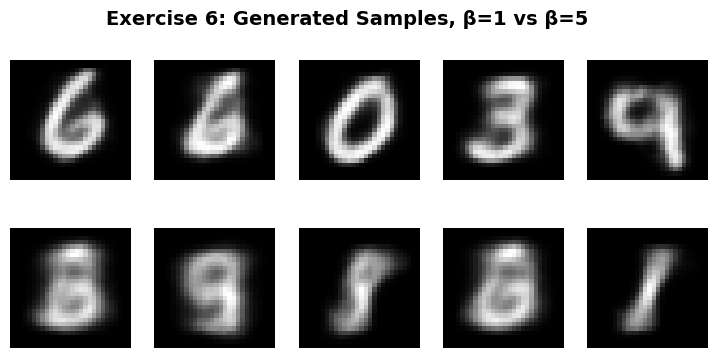

In [18]:
_, dec_beta5, _, m_beta5 = train_vae(2, beta=5.0)
gen_beta1 = dec.predict(rng_gen.standard_normal((25, LATENT)).astype('float32'), verbose=0)
gen_beta5 = dec_beta5.predict(rng_gen.standard_normal((25, LATENT)).astype('float32'), verbose=0)
print(pd.DataFrame([['beta = 1', *m_v], ['beta = 5', *m_beta5]],
                   columns=['Model', 'MSE', 'MAE', 'SSIM']).round(5).to_string(index=False))

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for i in range(5):
    axes[0, i].imshow(gen_beta1[i].reshape(28, 28), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(gen_beta5[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('β=1', rotation=0, ha='right'); axes[1, 0].set_ylabel('β=5', rotation=0, ha='right')
fig.suptitle('Exercise 6: Generated Samples, β=1 vs β=5', fontsize=14)
save(fig, '16_ex6_beta_vae_comparison.png')

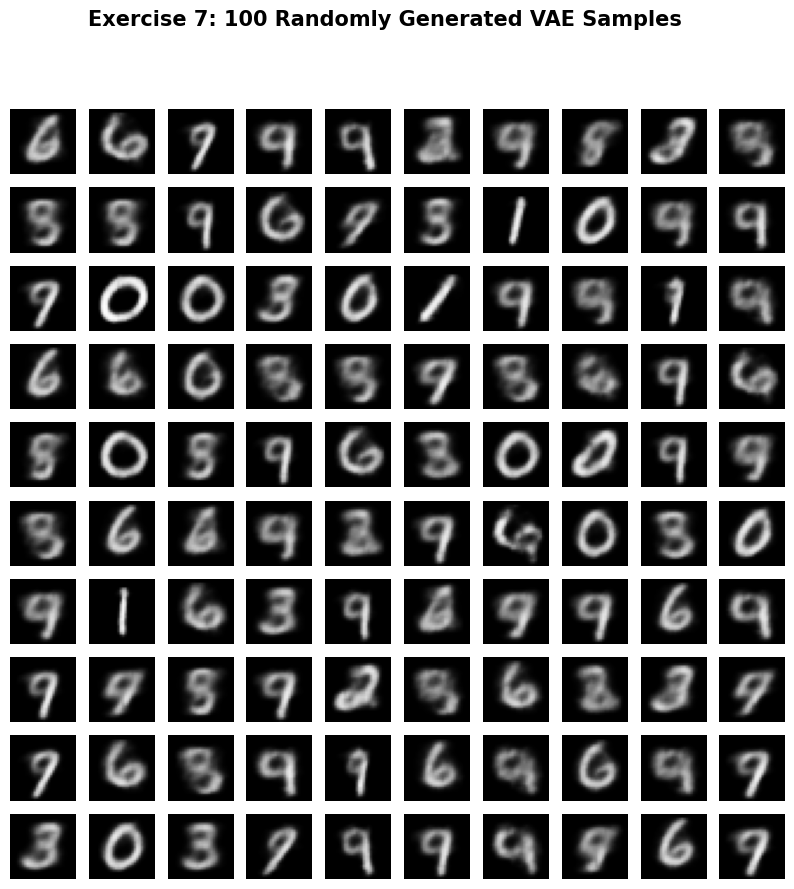

In [19]:
gen100 = dec.predict(rng_gen.standard_normal((100, LATENT)).astype('float32'), verbose=0)
fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(gen100[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1); ax.axis('off')
fig.suptitle('Exercise 7: 100 Randomly Generated VAE Samples', fontsize=15)
save(fig, '17_ex7_100_generated_samples.png')

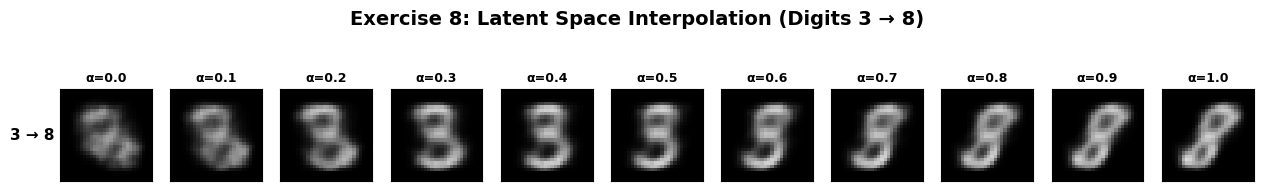

In [20]:
digit_C, digit_D = 3, 8
zC = mu_test[np.where(y_test == digit_C)[0][0]]
zD = mu_test[np.where(y_test == digit_D)[0][0]]
z_int2 = np.array([(1 - a) * zC + a * zD for a in alphas], dtype='float32')
interp2 = dec.predict(z_int2, verbose=0)
grid_rows([interp2], [f'{digit_C} → {digit_D}'], '18_ex8_interpolation_3to8.png',
          'Exercise 8: Latent Space Interpolation (Digits 3 → 8)', col_titles=[f'α={a}' for a in alphas])